# 01 — Fundamentação Matemática

## Objetivo
Construir uma série de preços simples e calcular retornos simples e logarítmicos, além de medidas descritivas.

## Conceitos
Para preços positivos \(P_t\) e \(P_{t-1}\):

- Retorno simples: \(R_t = P_t/P_{t-1} - 1\).
- Retorno logarítmico: \(r_t = \ln(P_t/P_{t-1})\).
- Retorno logarítmico acumulado: soma dos retornos logarítmicos consecutivos.

A soma dos retornos logarítmicos corresponde ao logaritmo da razão entre o preço final e o inicial. Retornos simples, por sua vez, são acumulados por composição multiplicativa.

# 1. Fundamentação Matemática

## 1.1 Retorno Simples

O retorno simples representa a variação percentual
do preço de um ativo entre dois períodos.

R_t = (P_t - P_{t-1}) / P_{t-1}

## 1.2 Retorno Logarítmico

O retorno logarítmico é definido por:

r_t = ln(P_t / P_{t-1})

Sua principal vantagem é a propriedade aditiva
ao longo do tempo.

## 1. Importação das bibliotecas

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["font.size"] = 11

## 2. Série de preços fictícia

In [37]:
precos = pd.Series(
    [100, 102, 101, 105, 108, 106, 110],
    name="Preco"
)

precos

0    100
1    102
2    101
3    105
4    108
5    106
6    110
Name: Preco, dtype: int64

## 3. Cálculo dos retornos

In [38]:
if (precos.dropna() <= 0).any():
    raise ValueError("Os preços precisam ser positivos para calcular retornos logarítmicos.")

dados = pd.DataFrame({"Preco": precos})
dados["Retorno_Simples"] = dados["Preco"].pct_change()
dados["Retorno_Log"] = np.log(dados["Preco"] / dados["Preco"].shift(1))

dados


,Preco,Retorno_Simples,Retorno_Log
0,100,NaN,NaN
1,102,0.020000,0.019803
2,101,-0.009804,-0.009852
3,105,0.039604,0.038840
4,108,0.028571,0.028171
5,106,-0.018519,-0.018692
6,110,0.037736,0.037041


## 4. Estatística descritiva
A variância e o desvio-padrão do Pandas usam, por padrão, a estimativa amostral (ddof=1).

In [39]:
retornos = dados["Retorno_Log"].dropna()

estatisticas = pd.Series({
    "quantidade": retornos.count(),
    "media": retornos.mean(),
    "variancia_amostral": retornos.var(),
    "desvio_padrao_amostral": retornos.std(),
    "minimo": retornos.min(),
    "maximo": retornos.max()
})

estatisticas

quantidade                6.000000
media                     0.015885
variancia_amostral        0.000600
desvio_padrao_amostral    0.024490
minimo                   -0.018692
maximo                    0.038840
dtype: float64

## 1.1 Análise dos Retornos Simples e Logarítmicos

A partir da série hipotética de preços, foram calculados os retornos simples e logarítmicos de cada período.

Os resultados demonstram que ambas as medidas representam as variações dos preços ao longo do tempo. Entretanto, apresentam diferenças matemáticas.

Observou-se que os retornos simples e logarítmicos possuem valores próximos para pequenas variações percentuais, embora não sejam numericamente iguais.

Os períodos 2 e 5 apresentaram retornos negativos, indicando desvalorização do ativo. Nos demais períodos, os retornos foram positivos, indicando valorização.

A primeira observação apresentou valor NaN porque não existe um preço anterior que permita calcular o retorno inicial.

Conclui-se que os retornos logarítmicos oferecem uma representação matemática conveniente para estudar séries temporais financeiras, especialmente devido à sua propriedade de aditividade temporal.

## 5. Visualização dos retornos

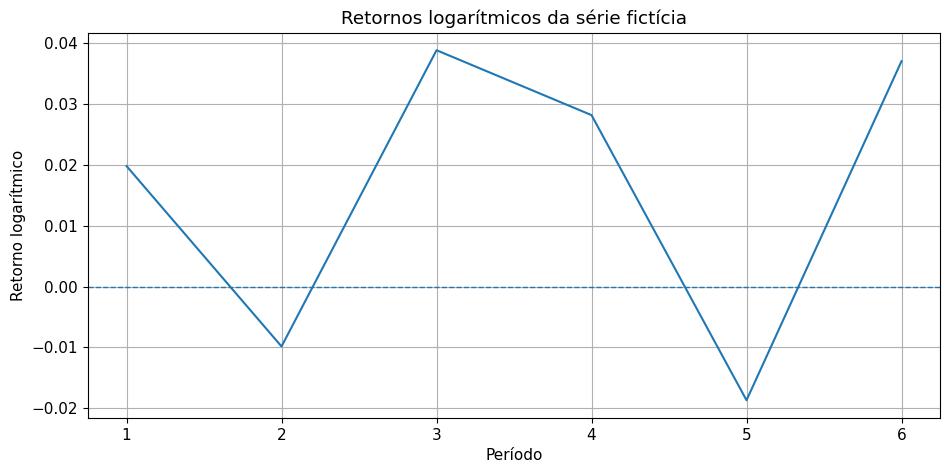

In [40]:
ax = retornos.plot(title="Retornos logarítmicos da série fictícia")
ax.axhline(0, linestyle="--", linewidth=1)
ax.set_xlabel("Período")
ax.set_ylabel("Retorno logarítmico")
ax.grid(True)
plt.show()

## 6. Verificação da propriedade aditiva
Compare a soma dos retornos logarítmicos com o logaritmo da razão entre o último e o primeiro preço.

In [41]:
soma_log = retornos.sum()
log_acumulado_direto = np.log(precos.iloc[-1] / precos.iloc[0])

print("Soma dos retornos log:", soma_log)
print("Log da razão final/inicial:", log_acumulado_direto)
print("Valores coincidem:", np.isclose(soma_log, log_acumulado_direto))

Soma dos retornos log: 0.09531017980432487
Log da razão final/inicial: 0.09531017980432493
Valores coincidem: True


## 7. Perguntas para interpretação
1. Por que foram calculados seis retornos a partir de sete preços?
2. Qual a diferença entre retorno simples e logarítmico?
3. O que a média representa nesta amostra?
4. O que o desvio-padrão informa sobre a dispersão?
5. Por que a propriedade aditiva é útil em séries temporais?

## 8. Limitações
A série é fictícia e muito curta. As estatísticas calculadas servem para aprender o método, não para inferir propriedades gerais de mercados financeiros.

## 9. Próxima etapa
Após validar este notebook, implementar as funções reutilizáveis em `src/statistical_analysis.py` e criar testes em `tests/test_statistics.py`.

## 1.3 Interpretação dos Resultados

Os retornos simples e logarítmicos apresentaram
valores próximos para pequenas variações de preço.

A propriedade aditiva dos retornos logarítmicos
foi validada numericamente.

Isso demonstra a possibilidade de representar
o retorno acumulado como a soma dos retornos
observados em períodos consecutivos.

# 2. Variáveis Aleatórias e Distribuições de Probabilidade

## 2.1 Variável Aleatória

Os retornos financeiros podem ser representados por variáveis aleatórias, uma vez que seus valores futuros são incertos.

Neste estudo, o retorno logarítmico é definido por:

\[
R_t = \ln\left(\frac{P_t}{P_{t-1}}\right)
\]

A variável aleatória pode assumir valores positivos, negativos ou iguais a zero, representando diferentes comportamentos dos preços dos ativos.

## 2.2 Distribuição de Probabilidade

Uma distribuição de probabilidade descreve como os possíveis valores de uma variável aleatória estão distribuídos.

Para variáveis contínuas, utiliza-se a função densidade de probabilidade \(f(r)\), que satisfaz:

\[
f(r)\geq 0
\]

\[
\int_{-\infty}^{+\infty}f(r)\,dr=1
\]

## 2.3 Esperança Matemática

A esperança matemática representa o valor médio teórico de uma variável aleatória.

Para uma variável contínua:

\[
E(R)=\int_{-\infty}^{+\infty}r f(r)\,dr
\]

A média amostral é utilizada como estimativa empírica dessa grandeza:

\[
\bar R=\frac{1}{n}\sum_{i=1}^{n}r_i
\]

## 2.4 Distribuição Normal

A distribuição normal é um modelo probabilístico contínuo caracterizado pela média \(\mu\) e pelo desvio-padrão \(\sigma\).

Sua função densidade é:

\[
f(r)=\frac{1}{\sigma\sqrt{2\pi}}
e^{-\frac{(r-\mu)^2}{2\sigma^2}}
\]

Esse modelo será utilizado como referência para investigar o comportamento estatístico dos retornos financeiros.

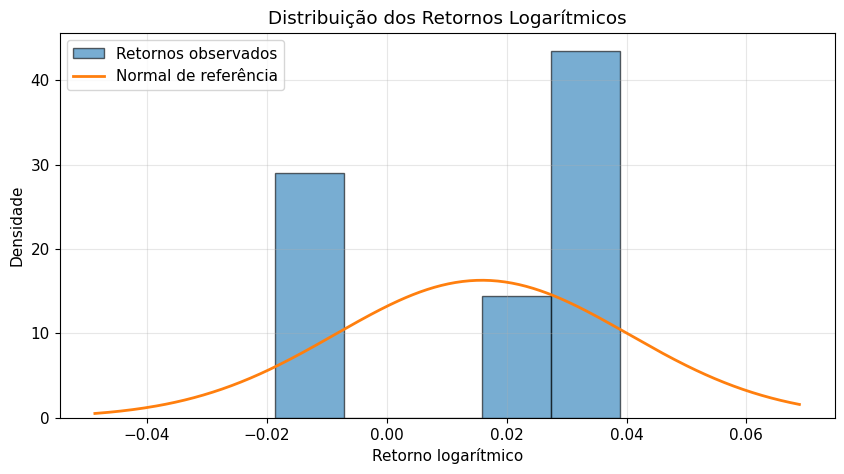

In [42]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Selecionando os retornos logarítmicos
retornos = dados["Retorno_Log"].dropna()

# Parâmetros estimados da amostra
media = retornos.mean()
desvio = retornos.std(ddof=1)

# Intervalo para a curva normal
x = np.linspace(
    retornos.min() - 0.03,
    retornos.max() + 0.03,
    300
)

# Densidade normal de referência
densidade_normal = norm.pdf(x, media, desvio)

# Histograma e curva
plt.figure(figsize=(10, 5))

plt.hist(
    retornos,
    bins=5,
    density=True,
    alpha=0.6,
    edgecolor="black",
    label="Retornos observados"
)

plt.plot(
    x,
    densidade_normal,
    linewidth=2,
    label="Normal de referência"
)

plt.title("Distribuição dos Retornos Logarítmicos")
plt.xlabel("Retorno logarítmico")
plt.ylabel("Densidade")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


In [43]:

# Esperança matemática estimada pela média amostral
esperanca_empirica = retornos.mean()

# Verificação da média
media_manual = sum(retornos) / len(retornos)

print(f"Esperança empírica: {esperanca_empirica:.6f}")
print(f"Média calculada manualmente: {media_manual:.6f}")

print(
    "Os resultados são iguais?",
    np.isclose(esperanca_empirica, media_manual)
)


Esperança empírica: 0.015885
Média calculada manualmente: 0.015885
Os resultados são iguais? True


In [35]:

from scipy.stats import skew, kurtosis

# Selecionar retornos logarítmicos válidos
retornos = dados["Retorno_Log"].dropna()

# Assimetria amostral corrigida
assimetria = skew(retornos, bias=False)

# Excesso de curtose amostral corrigido
curtose = kurtosis(
    retornos,
    fisher=True,
    bias=False
)

print(f"Assimetria: {assimetria:.6f}")
print(f"Excesso de curtose: {curtose:.6f}")

# Curtose convencional
curtose_convencional = curtose + 3

print(f"Curtose convencional: {curtose_convencional:.6f}")


Assimetria: -0.713012
Excesso de curtose: -1.639503
Curtose convencional: 1.360497


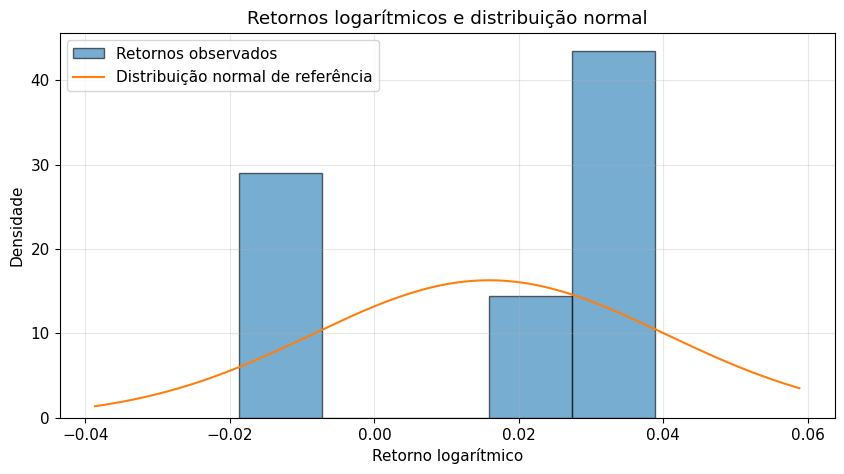

In [44]:

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm

media = retornos.mean()
desvio = retornos.std(ddof=1)

x = np.linspace(
    retornos.min() - 0.02,
    retornos.max() + 0.02,
    300
)

plt.figure(figsize=(10, 5))

plt.hist(
    retornos,
    bins=5,
    density=True,
    alpha=0.6,
    edgecolor="black",
    label="Retornos observados"
)

plt.plot(
    x,
    norm.pdf(x, media, desvio),
    label="Distribuição normal de referência"
)

plt.title("Retornos logarítmicos e distribuição normal")
plt.xlabel("Retorno logarítmico")
plt.ylabel("Densidade")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


## 2.5 Assimetria e Curtose

A assimetria e a curtose são medidas estatísticas utilizadas para caracterizar a forma de uma distribuição de probabilidade.

A assimetria mede o grau de falta de simetria da distribuição, enquanto a curtose está relacionada ao comportamento dos momentos de quarta ordem e às características das caudas.

Neste estudo, foram calculados:

- Assimetria amostral: aproximadamente -0,7130.
- Excesso de curtose amostral: aproximadamente -1,6395.

A assimetria negativa indica uma tendência de maior alongamento da cauda à esquerda na amostra observada.

O excesso de curtose negativo indica uma estimativa inferior à referência da distribuição normal.

Entretanto, devido à pequena quantidade de observações, esses resultados não permitem caracterizar definitivamente a distribuição dos retornos.

Essas medidas serão particularmente importantes nas próximas etapas, quando forem analisadas séries financeiras maiores e investigadas possíveis diferenças entre as distribuições empíricas e o modelo gaussiano.